# 04 — Model Development and Forecast Evaluation

## USD/LKR Exchange-Rate Forecasting Under Economic Regime Changes

This notebook compares a Naive baseline, ARIMA, GARCH volatility forecasts, XGBoost, MLPRegressor, and (when TensorFlow is available) LSTM. MLPRegressor ensures a second machine-learning model is evaluated if TensorFlow is unavailable. The main point-forecast comparison is one-step-ahead and uses the same chronological test target dates. XGBoost and LSTM predict the next log return and convert it back to a rate level, avoiding direct tree extrapolation of a trending price level. GARCH is evaluated as a volatility model rather than incorrectly compared with level forecasts using MAE/RMSE.

**Date-gap rule:** The primary one-step point-forecast sample is restricted to observations from 2014 onward where the next observation is no more than five calendar days away. Lags remain observation-based. A separate 2022 walk-forward analysis is used to examine performance around the exchange-rate regime change.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.optimize import minimize

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
try:
    import tensorflow as tf
    tf.random.set_seed(SEED)
    TENSORFLOW_AVAILABLE = True
except Exception as exc:
    TENSORFLOW_AVAILABLE = False
    print("TensorFlow unavailable; LSTM section will be skipped.", repr(exc))

DATA_PATH = Path("../data/processed/feature_engineered_dataset.csv")
MASTER_PATH = Path("../data/processed/master_dataset.csv")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists() or not MASTER_PATH.exists():
    raise FileNotFoundError("Run Notebooks 1 and 3 first so the processed datasets exist.")
features_df = pd.read_csv(DATA_PATH, parse_dates=["date", "Target_Date_1", "Target_Date_5", "Target_Date_20"])
master = pd.read_csv(MASTER_PATH, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
print("Feature data:", features_df.shape, "Master data:", master.shape)

Feature data: (3499, 24) Master data: (3499, 2)


## 2. Define a consistent one-step-ahead sample and time splits

Each row forecasts the next observed rate from information available at the current row. Long next-observation gaps are excluded from the primary comparison. Rows are split chronologically into train, validation, and test partitions (70% / 15% / 15%); random splitting is not used.

In [2]:
FEATURES = [
    "USD_LKR", "log_return", "days_since_previous_obs", "long_previous_gap",
    "Lag_1", "Lag_5", "Lag_20", "Return_Lag_1", "Return_Lag_5", "Return_Lag_20",
    "Rolling_Mean_5", "Rolling_Mean_20", "Rolling_Std_20", "rolling_volatility_20"
]

model_df = features_df.copy()
model_df["target_gap_days"] = (model_df["Target_Date_1"] - model_df["date"]).dt.days
model_df = model_df.loc[
    (model_df["date"] >= pd.Timestamp("2014-01-01")) &
    (model_df["target_gap_days"].between(1, 5))
].dropna(subset=FEATURES + ["Target_1", "Target_Return_1", "Target_Date_1"]).copy()
model_df = model_df.sort_values("date").reset_index(drop=True)

n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
train = model_df.iloc[:train_end].copy()
val = model_df.iloc[train_end:val_end].copy()
test = model_df.iloc[val_end:].copy()

print("Eligible observations:", n)
print("Train:", len(train), train["date"].min().date(), "to target", train["Target_Date_1"].max().date())
print("Validation:", len(val), val["date"].min().date(), "to target", val["Target_Date_1"].max().date())
print("Test:", len(test), test["date"].min().date(), "to target", test["Target_Date_1"].max().date())
assert train["Target_Date_1"].max() < val["Target_Date_1"].min()
assert val["Target_Date_1"].max() < test["Target_Date_1"].min()

Eligible observations: 3067
Train: 2146 2014-01-01 to target 2022-11-30
Validation: 460 2022-11-30 to target 2024-10-28
Test: 461 2024-10-28 to target 2026-09-25


## 3.Chronological modelling split and leakage prevention
The figure displays exchange-rate observations assigned to the training, validation, and test partitions. Time must flow forward: training data are earlier than validation data, and the final test period remains unseen during model selection.

Why this matters: Randomly shuffling time-series rows could allow a model to learn from information that would not have existed at the forecast origin. Chronological partitions better approximate a real forecasting workflow.

Check after execution: Confirm that date ranges are nonoverlapping and that every feature used for a forecast is available by its forecast origin. The plot uses feature dates; target dates may extend later and should also be checked for leakage.

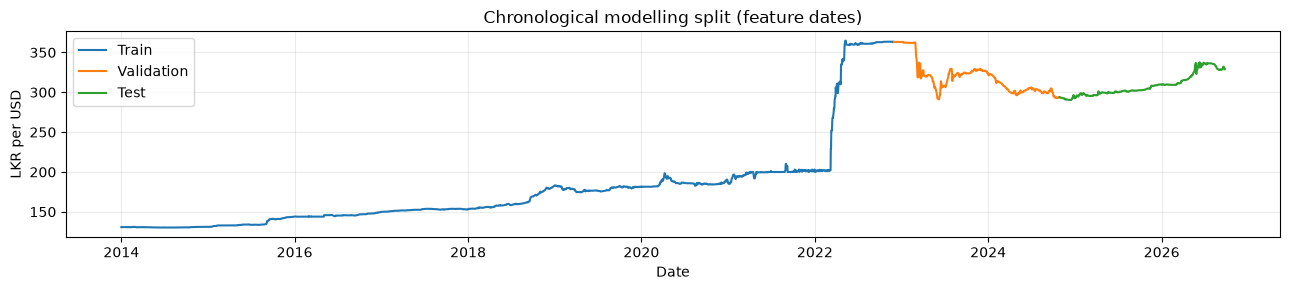

In [3]:
fig, ax = plt.subplots(figsize=(13, 3))
for name, frame in [("Train",train),("Validation",val),("Test",test)]:
    ax.plot(frame["date"], frame["USD_LKR"], label=name, lw=1.5)
ax.set(title="Chronological modelling split (feature dates)", xlabel="Date", ylabel="LKR per USD")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()


## 4. Evaluation metrics

MAE and RMSE are reported for rate-level forecasts. MASE and directional accuracy add context. Relative RMSE compares each point-forecast model with the Naive baseline on the same test rows. A Diebold–Mariano test is included for paired forecast errors, with the caveat that small differences should not be interpreted as meaningful without uncertainty analysis.

In [4]:
def metric_row(name, actual, predicted, naive=None, dates=None):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = actual - predicted
    mae = mean_absolute_error(actual, predicted)
    rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
    # MASE denominator: mean absolute one-step change in training levels.
    scale = float(np.mean(np.abs(np.diff(train["USD_LKR"].to_numpy()))))
    mase = mae / scale if scale > 0 else np.nan
    directional = np.nan
    if dates is not None and len(actual) == len(dates):
        # Direction vs current rate for each row (both actual and forecast).
        current = np.asarray(dates, dtype=float)
        actual_dir = np.sign(actual - current)
        pred_dir = np.sign(predicted - current)
        directional = float(np.mean(actual_dir == pred_dir))
    return {"Model": name, "MAE": mae, "RMSE": rmse, "MASE": mase, "Directional_Accuracy": directional}

def dm_test(loss_a, loss_b, h=1):
    """Approximate two-sided Diebold-Mariano test for paired absolute-loss differences."""
    d = np.asarray(loss_a, float) - np.asarray(loss_b, float)
    d = d[np.isfinite(d)]
    n_ = len(d)
    if n_ < 10 or np.var(d, ddof=1) == 0:
        return np.nan, np.nan
    mean_d = d.mean()
    # Newey-West variance of the mean difference; lag h-1 is zero for one-step.
    centered = d - mean_d
    gamma0 = np.dot(centered, centered) / n_
    long_var = gamma0
    for lag in range(1, min(h, n_ - 1)):
        gamma = np.dot(centered[lag:], centered[:-lag]) / n_
        long_var += 2 * (1 - lag / h) * gamma
    if long_var <= 0:
        return np.nan, np.nan
    stat = mean_d / np.sqrt(long_var / n_)
    from scipy.stats import norm
    p = 2 * (1 - norm.cdf(abs(stat)))
    return float(stat), float(p)

## 5. Expanding-window historical validation and interval backtesting

Run historical folds before model selection and test evaluation. The XGBoost configuration here is fixed in advance, not selected using future data. The interval diagnostic below is for the naive benchmark only; it does not establish coverage for other forecasting models.

In [5]:
# Four expanding-window folds; target-date purge prevents look-ahead.
wf_rows = []
for year in [2017, 2018, 2019, 2020]:
    start = pd.Timestamp(f"{year}-01-01")
    stop = pd.Timestamp(f"{year+1}-01-01")
    tr = model_df.loc[model_df["Target_Date_1"] < start]
    va = model_df.loc[(model_df["date"] >= start) & (model_df["Target_Date_1"] < stop)]
    if len(tr) < 40 or len(va) < 10: continue
    assert tr["Target_Date_1"].max() < va["date"].min()
    naive = va["USD_LKR"].to_numpy()
    reg = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1, **{"n_estimators":300,"max_depth":2,"learning_rate":0.03,"subsample":0.8,"colsample_bytree":0.8})
    reg.fit(tr[FEATURES], tr["Target_Return_1"])
    pred = naive * np.exp(reg.predict(va[FEATURES]))
    for name, p in [("Naive", naive), ("XGBoost-return", pred)]:
        wf_rows.append({"validation_year": year, "model": name, "n": len(va),
                        "MAE": mean_absolute_error(va["Target_1"], p),
                        "RMSE": np.sqrt(mean_squared_error(va["Target_1"], p))})
walk_forward_results = pd.DataFrame(wf_rows)
if not walk_forward_results.empty:
    display(walk_forward_results)
    walk_forward_results.to_csv(OUT_DIR / "expanding_window_validation.csv", index=False)


,validation_year,model,n,MAE,RMSE
0,2017,Naive,240,0.061918,0.095096
1,2017,XGBoost-return,240,0.109058,0.131655
2,2018,Naive,239,0.225368,0.332550
3,2018,XGBoost-return,239,0.216573,0.310036
4,2019,Naive,242,0.249317,0.359003
5,2019,XGBoost-return,242,0.316234,0.411591
6,2020,Naive,239,0.358496,0.682156
7,2020,XGBoost-return,239,0.631052,0.851924


## 6. Naive baseline

The baseline forecast is the current rate carried forward to the next observation. This is a meaningful benchmark for exchange rates that may behave approximately like a random walk.

In [6]:
y_val = val["Target_1"].to_numpy()
y_test = test["Target_1"].to_numpy()
naive_val = val["USD_LKR"].to_numpy()
naive_test = test["USD_LKR"].to_numpy()
naive_val_mae = mean_absolute_error(y_val, naive_val)
print("Naive validation MAE:", round(naive_val_mae, 6))

Naive validation MAE: 0.820131


## 7. ARIMA order selection and rolling one-step evaluation

ARIMA is fitted to the exchange-rate level with differencing. Candidate orders are compared on the validation period using rolling one-step forecasts. After each forecast, the observed value is appended to the model state, reflecting information that would have become available at that time. The final test is evaluated the same way.

In [7]:
def rolling_arima_predictions(history, actual_series, eval_dates, order):
    """Efficient rolling one-step forecasts using the state-space filter and fixed parameters."""
    history = history.astype(float).copy()
    fit = ARIMA(history.to_numpy(), order=order, enforce_stationarity=False, enforce_invertibility=False).fit()
    out = {}
    eval_dates = set(pd.to_datetime(eval_dates))
    if len(actual_series):
        extended = fit.extend(actual_series.to_numpy(dtype=float))
        forecasts = np.asarray(extended.forecasts).reshape(-1)
        for dt, pred in zip(actual_series.index, forecasts):
            if pd.Timestamp(dt) in eval_dates:
                out[pd.Timestamp(dt)] = float(pred)
    return out

rate_series = master.loc[master["date"] >= pd.Timestamp("2014-01-01")].set_index("date")["USD_LKR"].astype(float)
train_target_end = pd.Timestamp(train["Target_Date_1"].max())
val_target_end = pd.Timestamp(val["Target_Date_1"].max())
val_dates = pd.to_datetime(val["Target_Date_1"])
val_actual_series = rate_series.loc[(rate_series.index > train_target_end) & (rate_series.index <= val_target_end)]
history_train = rate_series.loc[rate_series.index <= train_target_end]

candidate_orders = [(0,1,0), (1,1,0), (0,1,1), (1,1,1)]
arima_validation_scores = []
for order in candidate_orders:
    try:
        pred_map = rolling_arima_predictions(history_train, val_actual_series, val_dates, order)
        preds = np.array([pred_map[pd.Timestamp(d)] for d in val_dates])
        score = mean_absolute_error(y_val, preds)
        arima_validation_scores.append({"order": order, "validation_MAE": score})
        print("ARIMA", order, "validation MAE:", round(score, 6))
    except Exception as exc:
        print("ARIMA order failed:", order, repr(exc))

if not arima_validation_scores:
    raise RuntimeError("All ARIMA candidates failed. Check the data and statsmodels installation.")
best_arima_order = min(arima_validation_scores, key=lambda x: x["validation_MAE"])["order"]
print("Selected ARIMA order by validation MAE:", best_arima_order)
pd.DataFrame(arima_validation_scores).sort_values("validation_MAE")

ARIMA (0, 1, 0) validation MAE: 0.820131
ARIMA (1, 1, 0) validation MAE: 0.805192
ARIMA (0, 1, 1) validation MAE: 0.809579
ARIMA (1, 1, 1) validation MAE: 0.802781
Selected ARIMA order by validation MAE: (1, 1, 1)


,order,validation_MAE
3,"(1, 1, 1)",0.802781
1,"(1, 1, 0)",0.805192
2,"(0, 1, 1)",0.809579
0,"(0, 1, 0)",0.820131


In [8]:
test_dates = pd.to_datetime(test["Target_Date_1"])
test_actual_end = pd.Timestamp(test["Target_Date_1"].max())
val_history = rate_series.loc[rate_series.index <= val_target_end]
test_actual_series = rate_series.loc[(rate_series.index > val_target_end) & (rate_series.index <= test_actual_end)]
arima_test_map = rolling_arima_predictions(val_history, test_actual_series, test_dates, best_arima_order)
arima_test = np.array([arima_test_map[pd.Timestamp(d)] for d in test_dates])
print("ARIMA test MAE:", round(mean_absolute_error(y_test, arima_test), 6))
print("ARIMA test RMSE:", round(np.sqrt(mean_squared_error(y_test, arima_test)), 6))

ARIMA test MAE: 0.406721
ARIMA test RMSE: 0.974414


## 8. XGBoost on next-observation log returns

XGBoost predicts `Target_Return_1`, then converts the predicted log return into an exchange-rate level using the current rate: `forecast = current_rate × exp(predicted_return)`. Hyperparameters are selected on validation MAE; the final test uses a model fitted on train plus validation data.

In [9]:
xgb_configs = [
    {"n_estimators": 300, "max_depth": 2, "learning_rate": 0.03, "subsample": 0.8, "colsample_bytree": 0.8},
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.03, "subsample": 0.8, "colsample_bytree": 0.8},
    {"n_estimators": 500, "max_depth": 2, "learning_rate": 0.02, "subsample": 0.8, "colsample_bytree": 0.8},
]
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]
yr_train, yr_val, yr_test = train["Target_Return_1"], val["Target_Return_1"], test["Target_Return_1"]
xgb_val_scores = []
for cfg in xgb_configs:
    model = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1, **cfg)
    model.fit(X_train, yr_train)
    val_return_pred = model.predict(X_val)
    val_rate_pred = val["USD_LKR"].to_numpy() * np.exp(val_return_pred)
    score = mean_absolute_error(y_val, val_rate_pred)
    xgb_val_scores.append({"config": cfg, "validation_MAE": score})
    print(cfg, "validation MAE:", round(score, 6))
best_xgb_config = min(xgb_val_scores, key=lambda x: x["validation_MAE"])["config"]
print("Selected XGBoost config:", best_xgb_config)

train_val = pd.concat([train, val]).sort_values("date")
xgb_model = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1, **best_xgb_config)
xgb_model.fit(train_val[FEATURES], train_val["Target_Return_1"])
xgb_test_return = xgb_model.predict(X_test)
xgb_test = test["USD_LKR"].to_numpy() * np.exp(xgb_test_return)
print("XGBoost test MAE:", round(mean_absolute_error(y_test, xgb_test), 6))
print("XGBoost test RMSE:", round(np.sqrt(mean_squared_error(y_test, xgb_test)), 6))

# MLPRegressor provides a second machine-learning model if TensorFlow/LSTM is unavailable.
# It predicts the next-observation log return, which is converted back to a rate level.
mlp_configs = [
    {"hidden_layer_sizes": (32,), "alpha": 0.001},
    {"hidden_layer_sizes": (32, 16), "alpha": 0.01},
]
mlp_validation_scores = []
for cfg in mlp_configs:
    mlp_candidate = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=cfg["hidden_layer_sizes"],
            alpha=cfg["alpha"],
            max_iter=500,
            early_stopping=False,
            random_state=SEED
        )
    )
    mlp_candidate.fit(X_train, yr_train)
    pred_return = mlp_candidate.predict(X_val)
    pred_rate = val["USD_LKR"].to_numpy() * np.exp(pred_return)
    mlp_validation_scores.append({"config": cfg, "validation_MAE": mean_absolute_error(y_val, pred_rate)})
best_mlp_config = min(mlp_validation_scores, key=lambda x: x["validation_MAE"])["config"]
train_val = pd.concat([train, val]).sort_values("date")
mlp_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=best_mlp_config["hidden_layer_sizes"],
        alpha=best_mlp_config["alpha"],
        max_iter=500,
        early_stopping=False,
        random_state=SEED
    )
)
mlp_model.fit(train_val[FEATURES], train_val["Target_Return_1"])
mlp_test_return = mlp_model.predict(X_test)
mlp_test = test["USD_LKR"].to_numpy() * np.exp(mlp_test_return)
mlp_val_best = min(mlp_validation_scores, key=lambda x: x["validation_MAE"])["validation_MAE"]
print("Selected MLP configuration:", best_mlp_config)
print("MLP validation MAE:", round(mlp_val_best, 6))
print("MLP test MAE:", round(mean_absolute_error(y_test, mlp_test), 6))
print("MLP test RMSE:", round(np.sqrt(mean_squared_error(y_test, mlp_test)), 6))


{'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8} validation MAE: 0.948216
{'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8} validation MAE: 0.928948
{'n_estimators': 500, 'max_depth': 2, 'learning_rate': 0.02, 'subsample': 0.8, 'colsample_bytree': 0.8} validation MAE: 0.960071
Selected XGBoost config: {'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8}
XGBoost test MAE: 0.4485
XGBoost test RMSE: 1.100929
Selected MLP configuration: {'hidden_layer_sizes': (32,), 'alpha': 0.001}
MLP validation MAE: 29.572412
MLP test MAE: 18.03075
MLP test RMSE: 22.014662


## 9. LSTM on aligned return sequences (optional dependency)

The LSTM uses the last 20 observed log returns to predict the next-observation log return. Target rows are aligned to the same `Target_1` / `Target_Date_1` convention as the other point-forecast models. Random seeds are set, the data are not shuffled, and early stopping monitors validation loss. If TensorFlow is not installed in the active notebook kernel, this section is skipped and the result is clearly marked unavailable.

In [10]:
lstm_test = None
lstm_validation_prediction = None
if TENSORFLOW_AVAILABLE:
    from sklearn.preprocessing import StandardScaler
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    tf.keras.utils.set_random_seed(SEED)

    LOOKBACK = 20
    # Use the full feature table so each sample's window includes the 20 observations before its forecast origin.
    raw_returns = features_df["log_return"].to_numpy(dtype=float)
    positions = model_df.index.to_numpy() if model_df.index.is_unique else None
    # Recreate stable positional indices against the unfiltered feature table using dates.
    date_to_pos = {pd.Timestamp(d): i for i, d in enumerate(features_df["date"])}
    positions = np.array([date_to_pos[pd.Timestamp(d)] for d in model_df["date"]])
    X_seq, y_seq = [], []
    for pos, target in zip(positions, model_df["Target_Return_1"].to_numpy()):
        if pos >= LOOKBACK - 1:
            window = raw_returns[pos-LOOKBACK+1:pos+1]
            if np.isfinite(window).all():
                X_seq.append(window.reshape(LOOKBACK, 1)); y_seq.append(target)
            else:
                X_seq.append(np.full((LOOKBACK, 1), np.nan)); y_seq.append(target)
        else:
            X_seq.append(np.full((LOOKBACK, 1), np.nan)); y_seq.append(target)
    X_seq = np.asarray(X_seq); y_seq = np.asarray(y_seq)
    good = np.isfinite(X_seq).all(axis=(1,2)) & np.isfinite(y_seq)
    seq_positions = np.where(good)[0]
    # Keep the original time split boundaries; remove only samples without a complete history.
    tr_idx = seq_positions[seq_positions < train_end]
    va_idx = seq_positions[(seq_positions >= train_end) & (seq_positions < val_end)]
    te_idx = seq_positions[seq_positions >= val_end]
    if len(tr_idx) > 30 and len(va_idx) > 10 and len(te_idx) > 10:
        scaler = StandardScaler()
        scaler.fit(X_seq[tr_idx].reshape(-1, 1))
        X_scaled = scaler.transform(X_seq.reshape(-1, 1)).reshape(X_seq.shape)
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        lstm_model = Sequential([LSTM(16, input_shape=(LOOKBACK, 1)), Dropout(0.1), Dense(8, activation="relu"), Dense(1)])
        lstm_model.compile(optimizer="adam", loss="mse")
        early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
        history = lstm_model.fit(X_scaled[tr_idx], y_seq[tr_idx], validation_data=(X_scaled[va_idx], y_seq[va_idx]),
                                 epochs=100, batch_size=32, shuffle=False, callbacks=[early_stop], verbose=0)
        val_ret_pred = lstm_model.predict(X_scaled[va_idx], verbose=0).ravel()
        lstm_validation_prediction = model_df.iloc[va_idx]["USD_LKR"].to_numpy() * np.exp(val_ret_pred)
        te_ret_pred = lstm_model.predict(X_scaled[te_idx], verbose=0).ravel()
        lstm_test = model_df.iloc[te_idx]["USD_LKR"].to_numpy() * np.exp(te_ret_pred)
        print("LSTM epochs run:", len(history.history["loss"]))
        print("LSTM test MAE:", round(mean_absolute_error(model_df.iloc[te_idx]["Target_1"], lstm_test), 6))
    else:
        print("LSTM skipped: not enough complete sequential samples after alignment.")
else:
    print("LSTM not run because TensorFlow is not installed in this kernel. Install TensorFlow in the selected environment and rerun this cell to include LSTM results.")

c:\Users\hasnd\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM epochs run: 23
LSTM test MAE: 0.511477


## 10. GARCH(1,1) volatility forecast

GARCH is not scored as an exchange-rate level model. The implementation below estimates a GARCH(1,1) conditional variance model on percentage log returns using maximum likelihood, then evaluates one-step volatility forecasts against realized squared returns using MSE and QLIKE. This avoids the invalid comparison of a volatility model's mean forecast with level-forecast MAE/RMSE.

In [11]:
def fit_garch11(returns_pct):
    x = np.asarray(returns_pct, dtype=float)
    x = x[np.isfinite(x)]
    mu = float(np.mean(x))
    eps = x - mu
    var0 = max(float(np.var(eps)), 1e-6)
    def nll(params):
        omega, alpha, beta = params
        if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 0.999:
            return 1e12
        h = np.empty(len(eps)); h[0] = var0
        for i in range(1, len(eps)):
            h[i] = omega + alpha * eps[i-1]**2 + beta * h[i-1]
        h = np.maximum(h, 1e-10)
        return 0.5 * np.sum(np.log(2*np.pi) + np.log(h) + eps**2/h)
    result = minimize(nll, x0=[var0*0.05, 0.08, 0.88], method="SLSQP",
                      bounds=[(1e-8, None), (0.0, 0.999), (0.0, 0.999)],
                      constraints=[{"type":"ineq", "fun": lambda p: 0.999 - p[1] - p[2]}],
                      options={"maxiter": 2000})
    if not result.success:
        warnings.warn("GARCH optimizer did not fully converge: " + str(result.message))
    omega, alpha, beta = result.x
    h = np.empty(len(eps)); h[0] = var0
    for i in range(1, len(eps)):
        h[i] = omega + alpha * eps[i-1]**2 + beta * h[i-1]
    return {"mu": mu, "omega": omega, "alpha": alpha, "beta": beta, "variance": h, "residuals": eps}

# Fit using returns observed through the final validation target date.
train_val_end = val_target_end
returns_history = master.loc[(master["date"] >= pd.Timestamp("2014-01-01")) & (master["date"] <= train_val_end)].copy()
returns_history["r_pct"] = np.log(returns_history["USD_LKR"]).diff() * 100
garch_fit = fit_garch11(returns_history["r_pct"].dropna())
print({k: round(garch_fit[k], 6) for k in ["mu", "omega", "alpha", "beta"]})

# Recursively generate one-step-ahead conditional variance forecasts.
# For each predictor date t, vol_map[t] forecasts the return from t to the next observation.
all_returns = master.loc[master["date"] >= pd.Timestamp("2014-01-01"), ["date", "USD_LKR"]].copy()
all_returns["r_pct"] = np.log(all_returns["USD_LKR"]).diff() * 100
mu, omega, alpha, beta = garch_fit["mu"], garch_fit["omega"], garch_fit["alpha"], garch_fit["beta"]
unconditional_var = omega / max(1.0 - alpha - beta, 1e-6)
h_prev = max(float(unconditional_var), 1e-8)
e_prev = 0.0
vol_map = {}
for _, row in all_returns.iterrows():
    dt = pd.Timestamp(row["date"])
    # h_current is the conditional variance of the return observed at this date.
    h_current = max(omega + alpha * e_prev**2 + beta * h_prev, 1e-8)
    if pd.notna(row["r_pct"]):
        e_current = float(row["r_pct"] - mu)
        # After observing the return at t, forecast variance for the next return t+1.
        h_next = max(omega + alpha * e_current**2 + beta * h_current, 1e-8)
        e_prev = e_current
        h_prev = h_current
    else:
        h_next = h_current
        h_prev = h_current
    vol_map[dt] = h_next

# Match each target return to the variance forecast made at its predictor date.
actual_sq, variance_forecasts = [], []
rate_index = all_returns.set_index("date")
for _, row in test.iterrows():
    target_date = pd.Timestamp(row["Target_Date_1"])
    predictor_date = pd.Timestamp(row["date"])
    if target_date in rate_index.index and predictor_date in vol_map:
        realized_return_pct = np.log(float(rate_index.loc[target_date, "USD_LKR"]) / float(row["USD_LKR"])) * 100
        actual_sq.append(realized_return_pct**2)
        variance_forecasts.append(vol_map[predictor_date])
actual_sq = np.asarray(actual_sq); variance_forecasts = np.maximum(np.asarray(variance_forecasts), 1e-8)
qlike = np.mean(np.log(variance_forecasts) + actual_sq / variance_forecasts)
vol_mse = mean_squared_error(actual_sq, variance_forecasts)
print("GARCH test volatility MSE (variance vs squared return):", round(vol_mse, 6))
print("GARCH test QLIKE (lower is better):", round(float(qlike), 6))

{'mu': 0.031017, 'omega': np.float64(0.005061), 'alpha': np.float64(0.213364), 'beta': np.float64(0.782614)}
GARCH test volatility MSE (variance vs squared return): 0.411381
GARCH test QLIKE (lower is better): -2.46633


## 11. Main test-set comparison

Naive, ARIMA, XGBoost-return, and MLP-return forecast the same next-observation rate and are included in the MAE/RMSE comparison. GARCH is reported separately with volatility metrics. Validation results determine ARIMA order and XGBoost hyperparameters; test results are reserved for final comparison.

In [12]:
comparison_rows = []
comparison_rows.append(metric_row("Naive", y_test, naive_test, dates=test["USD_LKR"].to_numpy()))
comparison_rows.append(metric_row("ARIMA" + str(best_arima_order), y_test, arima_test, dates=test["USD_LKR"].to_numpy()))
comparison_rows.append(metric_row("XGBoost-return", y_test, xgb_test, dates=test["USD_LKR"].to_numpy()))
comparison_rows.append(metric_row("MLP-return", y_test, mlp_test, dates=test["USD_LKR"].to_numpy()))
if lstm_test is not None:
    # LSTM may have fewer eligible sequence rows; compare its matching test subset only and mark sample count.
    good_test_idx = np.where(np.isfinite(X_seq).all(axis=(1,2)) & np.isfinite(y_seq))[0]
    lstm_idx = good_test_idx[good_test_idx >= val_end]
    actual_lstm = model_df.iloc[lstm_idx]["Target_1"].to_numpy()
    current_lstm = model_df.iloc[lstm_idx]["USD_LKR"].to_numpy()
    comparison_rows.append(metric_row("LSTM-return", actual_lstm, lstm_test, dates=current_lstm))
comparison = pd.DataFrame(comparison_rows)
naive_rmse = float(comparison.loc[comparison["Model"] == "Naive", "RMSE"].iloc[0])
comparison["Relative_RMSE_vs_Naive"] = comparison["RMSE"] / naive_rmse
comparison["Test_Observations"] = len(test)
comparison = comparison.sort_values("MAE").reset_index(drop=True)
comparison

,Model,MAE,RMSE,MASE,Directional_Accuracy,Relative_RMSE_vs_Naive,Test_Observations
0,"ARIMA(1, 1, 1)",0.406721,0.974414,1.303866,0.620390,1.028479,461
1,Naive,0.424284,0.947432,1.360170,0.002169,1.000000,461
2,XGBoost-return,0.448500,1.100929,1.437801,0.611714,1.162013,461
3,LSTM-return,0.511477,0.982958,1.639693,0.581345,1.037497,461
4,MLP-return,18.030750,22.014662,57.802932,0.568330,23.236130,461


## 12.Common-test accuracy and forecast residual diagnostics
The left chart compares model mean absolute error (MAE) on the same held-out test observations. MAE is the average absolute difference between the actual and predicted LKR-per-USD exchange rate; lower is better.

The right chart plots residuals defined as actual minus predicted. Values above zero indicate underprediction, and values below zero indicate overprediction. Long runs on one side of zero suggest systematic bias; isolated spikes suggest unusually large misses.

Interpretation: Compare models using the same forecast horizon, target dates, and test sample. Limitation: A small MAE difference is not automatically statistically meaningful, and strong one-step results do not imply strong long-horizon performance.

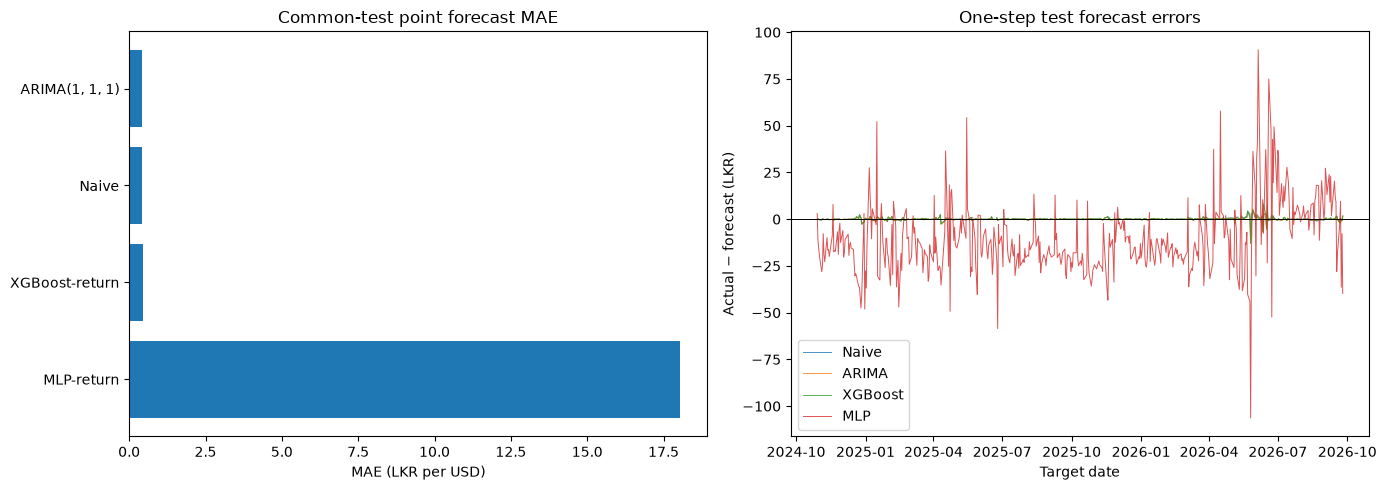

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
point_comp = comparison.loc[comparison["Model"].ne("LSTM-return")].copy()
axes[0].barh(point_comp["Model"], point_comp["MAE"])
axes[0].invert_yaxis(); axes[0].set(title="Common-test point forecast MAE", xlabel="MAE (LKR per USD)")
for label, pred in [("Naive",naive_test),("ARIMA",arima_test),("XGBoost",xgb_test),("MLP",mlp_test)]:
    axes[1].plot(test["Target_Date_1"], y_test - pred, lw=.7, label=label, alpha=.8)
axes[1].axhline(0, color="black", lw=.7)
axes[1].set(title="One-step test forecast errors", xlabel="Target date", ylabel="Actual − forecast (LKR)")
axes[1].legend(); plt.tight_layout(); plt.show()


In [14]:
# Paired Diebold-Mariano-style test on absolute errors for models evaluated on the same test rows.
dm_rows = []
model_predictions = {"Naive": naive_test, "ARIMA": arima_test, "XGBoost-return": xgb_test, "MLP-return": mlp_test}
for name, pred in model_predictions.items():
    if name == "Naive":
        continue
    stat, pval = dm_test(np.abs(y_test - pred), np.abs(y_test - naive_test), h=1)
    dm_rows.append({"Model_vs_Naive": name, "DM_statistic": stat, "p_value": pval})
dm_results = pd.DataFrame(dm_rows)
dm_results

,Model_vs_Naive,DM_statistic,p_value
0,ARIMA,-2.597451,0.009392
1,XGBoost-return,1.240074,0.214948
2,MLP-return,30.577454,0.000000


## 13.Interval coverage diagnostic — naive baseline

Validation residuals calibrate an approximate 95% interval for the naive benchmark; untouched test observations measure empirical coverage. This is **not** an interval for the selected machine-learning model.

In [15]:
# Evaluate approximate validation-calibrated residual intervals on untouched test forecasts.
validation_residuals = val["Target_1"].to_numpy() - val["USD_LKR"].to_numpy()
lo, hi = np.quantile(validation_residuals, [.025, .975])
pi_lower, pi_upper = naive_test + lo, naive_test + hi
coverage = np.mean((y_test >= pi_lower) & (y_test <= pi_upper))
interval_diagnostics = pd.DataFrame([{"method": "Naive validation-residual quantiles",
    "nominal_coverage": .95, "test_coverage": coverage,
    "mean_width": float(np.mean(pi_upper-pi_lower)), "test_n": len(test)}])
display(interval_diagnostics)
interval_diagnostics.to_csv(OUT_DIR / "interval_backtest.csv", index=False)

,method,nominal_coverage,test_coverage,mean_width,test_n
0,Naive validation-residual quantiles,0.95,0.984816,6.386883,461


## 14.Uncertainty intervals for the naive benchmark
The solid lines compare actual exchange rates with naive one-step predictions. The shaded region is an approximately 95% prediction interval calibrated from validation residuals. It represents a range of plausible future observations under the calibration assumptions.

The title reports empirical coverage: the fraction of test observations lying within the interval. A nominal 95% interval does not guarantee exactly 95% coverage on any particular test set.

Interpretation: Assess both whether the interval captures actual values and whether it is narrow enough to be useful. Limitation: Structural breaks, serial dependence, or distribution shifts can invalidate calibration; this is a prediction interval, not a confidence interval for the mean.

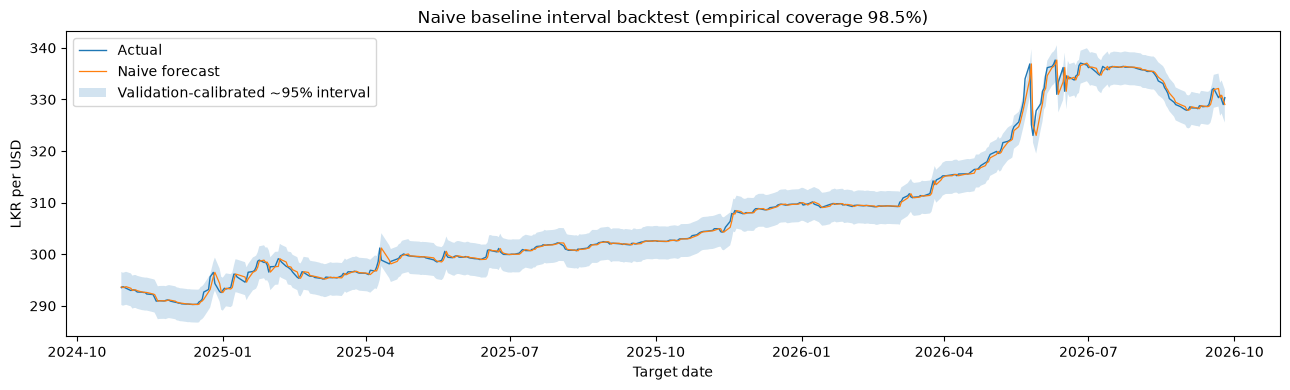

In [16]:
plt.figure(figsize=(13, 4))
plt.plot(test["Target_Date_1"], y_test, label="Actual", lw=1)
plt.plot(test["Target_Date_1"], naive_test, label="Naive forecast", lw=.9)
plt.fill_between(test["Target_Date_1"], pi_lower, pi_upper, alpha=.2, label="Validation-calibrated ~95% interval")
plt.title(f"Naive baseline interval backtest (empirical coverage {coverage:.1%})")
plt.xlabel("Target date"); plt.ylabel("LKR per USD"); plt.legend(); plt.tight_layout(); plt.show()


## 15. XGBoost feature importance and forecast plot

Feature importance is a model-specific diagnostic, not a causal explanation. Correlated predictors can share or redistribute importance.

In [17]:
importance = pd.DataFrame({"Feature": FEATURES, "Importance": xgb_model.feature_importances_}).sort_values("Importance", ascending=False)
importance

,Feature,Importance
12,Rolling_Std_20,0.170780
6,Lag_20,0.112598
5,Lag_5,0.097691
13,rolling_volatility_20,0.087701
0,USD_LKR,0.080576
10,Rolling_Mean_5,0.080464
1,log_return,0.070843
4,Lag_1,0.069719
7,Return_Lag_1,0.067477
11,Rolling_Mean_20,0.046185


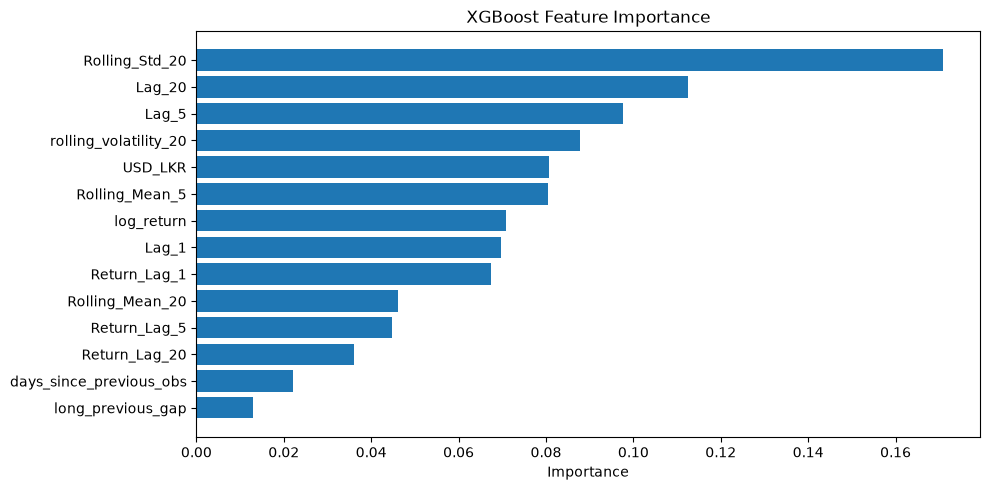

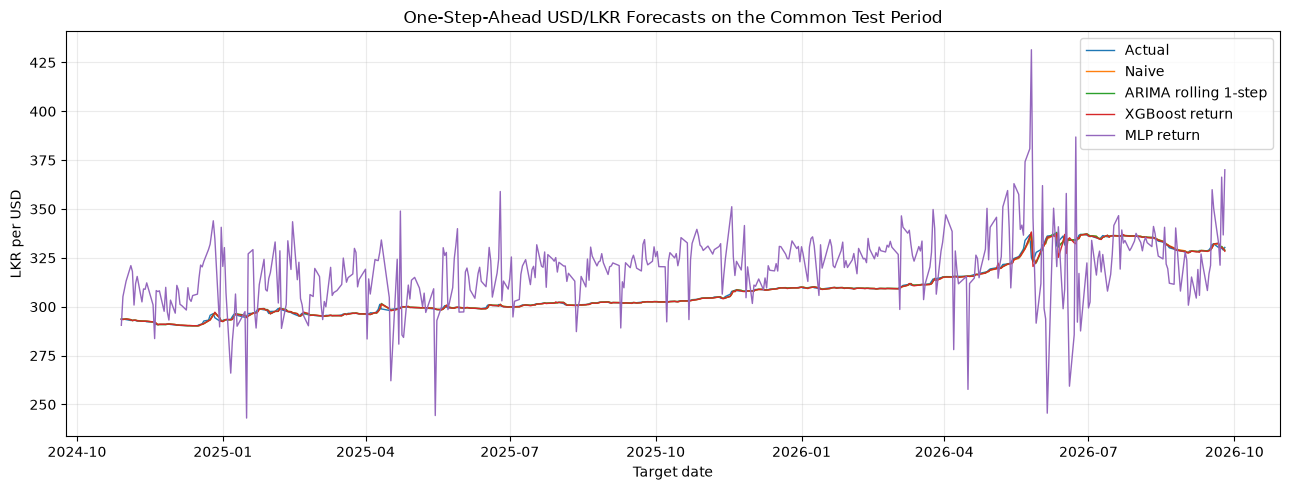

In [18]:
plt.figure(figsize=(10, 5))
plt.barh(importance["Feature"][::-1], importance["Importance"][::-1])
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 5))
plt.plot(test["Target_Date_1"], y_test, label="Actual", linewidth=1)
plt.plot(test["Target_Date_1"], naive_test, label="Naive", linewidth=1)
plt.plot(test["Target_Date_1"], arima_test, label="ARIMA rolling 1-step", linewidth=1)
plt.plot(test["Target_Date_1"], xgb_test, label="XGBoost return", linewidth=1)
plt.plot(test["Target_Date_1"], mlp_test, label="MLP return", linewidth=1)
plt.title("One-Step-Ahead USD/LKR Forecasts on the Common Test Period")
plt.xlabel("Target date"); plt.ylabel("LKR per USD"); plt.legend(); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 16. Additional aspect: 1-, 5-, and 20-observation horizons

This supplementary analysis compares direct-horizon Naive and XGBoost forecasts. For each horizon, the target is the cumulative log return from the current rate to the rate h observations ahead, converted back to a level. The same chronological split boundaries are used; the last available rows without that horizon's target are naturally excluded.

In [19]:
horizon_rows = []
for horizon in [1, 5, 20]:
    target_col = f"Target_Return_{horizon}"
    rate_col = f"Target_{horizon}"
    hdf = features_df.copy()
    hdf["target_gap_days"] = (hdf[f"Target_Date_{horizon}"] - hdf["date"]).dt.days
    hdf = hdf.loc[(hdf["date"] >= pd.Timestamp("2014-01-01"))].dropna(subset=FEATURES + [target_col, rate_col]).copy()
    # Purge any training target that is not observed before the next split begins.
    val_start = pd.Timestamp(val["date"].min())
    test_start = pd.Timestamp(test["date"].min())
    target_date_col = f"Target_Date_{horizon}"
    h_train = hdf.loc[hdf[target_date_col] < val_start].copy()
    h_val = hdf.loc[(hdf["date"] >= val_start) & (hdf[target_date_col] < test_start)].copy()
    h_test = hdf.loc[hdf["date"] >= test_start].copy()
    assert h_train[target_date_col].max() < val_start if len(h_train) else True
    assert h_val[target_date_col].max() < test_start if len(h_val) else True
    if min(len(h_train), len(h_val), len(h_test)) < 20:
        continue
    # Select one modest XGBoost configuration on validation MAE.
    hmodel = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1,
                          n_estimators=300, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8)
    hmodel.fit(h_train[FEATURES], h_train[target_col])
    hval_pred = h_val["USD_LKR"].to_numpy() * np.exp(hmodel.predict(h_val[FEATURES]))
    # Refit using train + validation after configuration is fixed.
    htrainval = pd.concat([h_train, h_val]).sort_values("date")
    hmodel.fit(htrainval[FEATURES], htrainval[target_col])
    hxgb = h_test["USD_LKR"].to_numpy() * np.exp(hmodel.predict(h_test[FEATURES]))
    hactual = h_test[rate_col].to_numpy()
    hnaive = h_test["USD_LKR"].to_numpy()
    horizon_rows.append({"Horizon_observations": horizon, "Model": "Naive", "N_test": len(h_test),
                         "MAE": mean_absolute_error(hactual, hnaive), "RMSE": np.sqrt(mean_squared_error(hactual, hnaive))})
    horizon_rows.append({"Horizon_observations": horizon, "Model": "XGBoost-return", "N_test": len(h_test),
                         "MAE": mean_absolute_error(hactual, hxgb), "RMSE": np.sqrt(mean_squared_error(hactual, hxgb))})
horizon_results = pd.DataFrame(horizon_rows)
horizon_results

,Horizon_observations,Model,N_test,MAE,RMSE
0,1,Naive,461,0.424284,0.947432
1,1,XGBoost-return,461,0.435467,1.027742
2,5,Naive,457,1.115646,1.856010
3,5,XGBoost-return,457,1.481003,2.168693
4,20,Naive,442,2.748674,4.088248
5,20,XGBoost-return,442,4.552666,6.143642


## 17.Forecast accuracy at different observation horizons
This line chart compares MAE at 1, 5, and 20 observations ahead for models included in the horizon analysis. Each point measures the average absolute error at that forecast horizon.

Interpretation: Increasing errors with longer horizons would indicate that more distant predictions are harder; crossings between lines indicate that the preferred model may depend on the decision horizon.

Important: An observation horizon is not a fixed number of calendar days because weekends, holidays, and missing dates create irregular gaps. Compare methods only where the underlying evaluation dates and forecast-origin information are aligned.

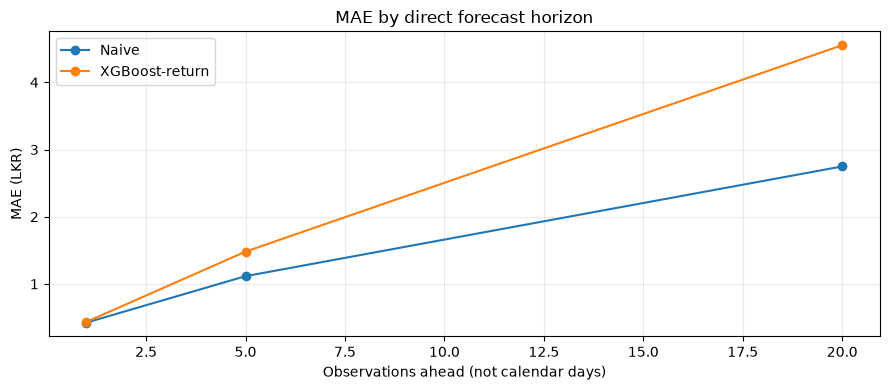

In [20]:
if len(horizon_results):
    fig, ax = plt.subplots(figsize=(9, 4))
    for name, part in horizon_results.groupby("Model"):
        ax.plot(part["Horizon_observations"], part["MAE"], marker="o", label=name)
    ax.set(title="MAE by direct forecast horizon", xlabel="Observations ahead (not calendar days)", ylabel="MAE (LKR)")
    ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()


## 18. Additional aspect: historical 2022 regime-change window

The primary holdout test period is recent and does not include the March 2022 shock. This supplementary analysis therefore trains an XGBoost return model using observations available through 2021 and evaluates one-step forecasts during 2022. The forecasts are static-model walk-forward predictions: after each date, the realized observation becomes part of the history for constructing subsequent features, but model parameters are not retrained during the crisis window. This is a separate historical stress test and should not be confused with the main test score.

In [21]:
crisis_features = features_df.copy()
crisis_features["target_gap_days"] = (crisis_features["Target_Date_1"] - crisis_features["date"]).dt.days
crisis_features = crisis_features.dropna(subset=FEATURES + ["Target_1", "Target_Return_1", "Target_Date_1"])
crisis_train = crisis_features.loc[(crisis_features["date"] >= pd.Timestamp("2014-01-01")) &
                                   (crisis_features["Target_Date_1"] < pd.Timestamp("2022-01-01")) &
                                   crisis_features["target_gap_days"].between(1,5)]
crisis_test = crisis_features.loc[(crisis_features["Target_Date_1"] >= pd.Timestamp("2022-01-01")) &
                                  (crisis_features["Target_Date_1"] <= pd.Timestamp("2022-12-31")) &
                                  crisis_features["target_gap_days"].between(1,5)]
if len(crisis_train) > 100 and len(crisis_test) > 20:
    crisis_model = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=1,
                                n_estimators=300, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8)
    crisis_model.fit(crisis_train[FEATURES], crisis_train["Target_Return_1"])
    crisis_pred = crisis_test["USD_LKR"].to_numpy() * np.exp(crisis_model.predict(crisis_test[FEATURES]))
    crisis_actual = crisis_test["Target_1"].to_numpy()
    crisis_naive = crisis_test["USD_LKR"].to_numpy()
    crisis_summary = pd.DataFrame([
        {"Period": "2022 fixed-origin historical stress test", "Model": "Naive", "N": len(crisis_test),
         "MAE": mean_absolute_error(crisis_actual, crisis_naive), "RMSE": np.sqrt(mean_squared_error(crisis_actual, crisis_naive))},
        {"Period": "2022 fixed-origin historical stress test", "Model": "XGBoost-return", "N": len(crisis_test),
         "MAE": mean_absolute_error(crisis_actual, crisis_pred), "RMSE": np.sqrt(mean_squared_error(crisis_actual, crisis_pred))}
    ])
    display(crisis_summary)
else:
    print("Insufficient eligible observations for the 2022 stress test after the date-gap rule.")

,Period,Model,N,MAE,RMSE
0,2022 fixed-origin historical stress test,Naive,239,1.111523,3.618012
1,2022 fixed-origin historical stress test,XGBoost-return,239,4.679923,6.154374


## 19.Forecast behavior during the 2022 exchange-rate shock
The first panel compares actual rates with naive and XGBoost one-step predictions during the selected historical crisis window. The second panel summarizes the corresponding error behavior as defined by the stress-test code.

Purpose: A model with low error in a relatively stable period may behave differently when the exchange-rate regime changes sharply. This stress test helps reveal sensitivity to exceptional market conditions.

Interpretation: Look for delayed responses, persistent bias, and large errors around abrupt shifts. Limitation: A retrospective stress test is not automatically an independent out-of-sample test; inspect the training cutoff and feature availability before drawing performance conclusions.

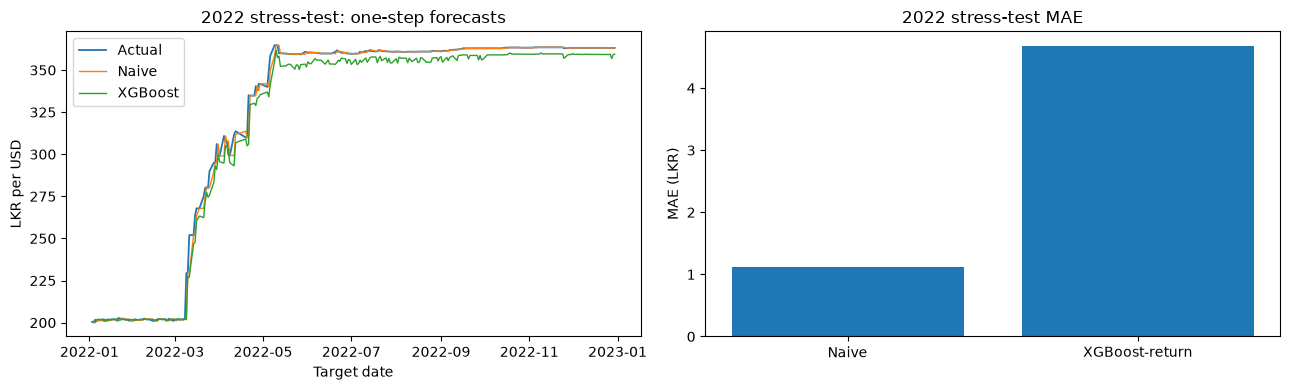

In [22]:
if "crisis_summary" in globals() and len(crisis_summary):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(crisis_test["Target_Date_1"], crisis_actual, label="Actual", lw=1.3)
    axes[0].plot(crisis_test["Target_Date_1"], crisis_naive, label="Naive", lw=1)
    axes[0].plot(crisis_test["Target_Date_1"], crisis_pred, label="XGBoost", lw=1)
    axes[0].set(title="2022 stress-test: one-step forecasts", xlabel="Target date", ylabel="LKR per USD")
    axes[0].legend()
    axes[1].bar(crisis_summary["Model"], crisis_summary["MAE"])
    axes[1].set(title="2022 stress-test MAE", ylabel="MAE (LKR)")
    plt.tight_layout(); plt.show()


## 20. Save reproducible results and model-selection metadata

The saved comparison contains only point-forecast models evaluated on the common main test rows. GARCH volatility metrics, multi-horizon metrics, 2022 stress-test metrics, and validation choices are saved separately to avoid mixing different tasks.

In [23]:
comparison_path = OUT_DIR / "corrected_model_comparison.csv"
comparison.to_csv(comparison_path, index=False)
if len(dm_results): dm_results.to_csv(OUT_DIR / "diebold_mariano_vs_naive.csv", index=False)
if len(horizon_results): horizon_results.to_csv(OUT_DIR / "multi_horizon_results.csv", index=False)
if 'crisis_summary' in globals(): crisis_summary.to_csv(OUT_DIR / "regime_2022_results.csv", index=False)
garch_metrics = pd.DataFrame([{
    "Model": "GARCH(1,1)",
    "Variance_MSE_vs_Squared_Return": float(vol_mse),
    "QLIKE": float(qlike),
    "Test_Observations": int(len(actual_sq)),
    "Return_Scale": "percentage log returns"
}])
garch_metrics.to_csv(OUT_DIR / "garch_volatility_metrics.csv", index=False)
pd.DataFrame(mlp_validation_scores).to_csv(OUT_DIR / "mlp_validation_scores.csv", index=False)

metadata = {
    "best_arima_order": list(best_arima_order),
    "best_xgb_config": best_xgb_config,
    "selected_point_forecast_model_by_validation": min(
        [("Naive", float(naive_val_mae)),
         ("ARIMA", float(min(arima_validation_scores, key=lambda x: x["validation_MAE"])["validation_MAE"])),
         ("XGBoost-return", float(min(xgb_val_scores, key=lambda x: x["validation_MAE"])["validation_MAE"])),
         ("MLP-return", float(mlp_val_best))],
        key=lambda item: item[1]
    )[0],
    "naive_validation_MAE": float(naive_val_mae),
    "arima_validation_MAE": float(min(arima_validation_scores, key=lambda x: x["validation_MAE"])["validation_MAE"]),
    "xgboost_validation_MAE": float(min(xgb_val_scores, key=lambda x: x["validation_MAE"])["validation_MAE"]),
    "best_mlp_config": {"hidden_layer_sizes": list(best_mlp_config["hidden_layer_sizes"]), "alpha": best_mlp_config["alpha"]},
    "mlp_validation_MAE": float(mlp_val_best),
    "last_available_date": str(master["date"].max().date()),
    "seed": SEED,
    "lstm_available": bool(TENSORFLOW_AVAILABLE and lstm_test is not None),
    "garch_evaluation": "volatility MSE and QLIKE; not level MAE/RMSE"
}
with open(OUT_DIR / "forecast_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Saved:", comparison_path)
print(json.dumps(metadata, indent=2))

Saved: ..\data\processed\corrected_model_comparison.csv
{
  "best_arima_order": [
    1,
    1,
    1
  ],
  "best_xgb_config": {
    "n_estimators": 300,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8
  },
  "selected_point_forecast_model_by_validation": "ARIMA",
  "naive_validation_MAE": 0.8201308695652155,
  "arima_validation_MAE": 0.8027808561202152,
  "xgboost_validation_MAE": 0.9289477391133345,
  "best_mlp_config": {
    "hidden_layer_sizes": [
      32
    ],
    "alpha": 0.001
  },
  "mlp_validation_MAE": 29.57241176352674,
  "last_available_date": "2026-09-25",
  "seed": 42,
  "lstm_available": true,
  "garch_evaluation": "volatility MSE and QLIKE; not level MAE/RMSE"
}


## 21. Diagnostics and interpretation prompts

- Compare the point-forecast models on the same test targets; do not interpret GARCH volatility scores as if they were rate-level MAE/RMSE.
- Explain why a random-walk-like exchange rate can make the Naive baseline competitive.
- ARIMA is updated with each observed value, so its result is rolling one-step, not a single long-horizon forecast.
- XGBoost and MLPRegressor model returns, then reconstruct the rate level. LSTM also models returns when TensorFlow is available. Their results can still be unstable around policy shifts.
- Use the feature-importance plot cautiously because rolling means and lagged levels are correlated.
- The 2022 stress-test is a separate historical evaluation; discuss the pegged period through 8 March separately from the post-9 March floating/shock period.
- The gap rule and 2014 start date improve comparability but reduce the sample and may exclude some meaningful long-gap movements.
- Report the actual output values generated when you rerun the notebook; do not reuse old markdown metrics.

## 22. Conclusion

The final model should be selected based on validation performance and assessed once on the untouched test period. The test comparison, the GARCH volatility analysis, the multi-horizon analysis, and the 2022 stress test answer different questions and should be reported separately. A small MAE difference does not establish statistical superiority; inspect the paired test and the magnitude of the errors before making a financial recommendation.